In [1]:
experiement_pth = '../test_results/evals'
analysis_pth = '../test_results/plots/'
print('Hello World')

Hello World


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import MultipleLocator
from IPython.display import Image, display

def compare_loss_curves(models, labels, losses=['total loss'], path="", yscales=['linear'], interval=10):

    ### Check if save directory exists
    os.makedirs(os.path.join(experiement_pth, path), exist_ok=True)

    
    # Plot each loss
    for i, loss in enumerate(losses):
        plt.close()
        plt.title(loss)
        for j, mdl in enumerate(models):
            df = pd.read_csv(os.path.join(mdl, 'losses.csv'))
            plt.plot(df[loss][::interval], label=labels[j])
        plt.yscale(yscales[i])
        plt.legend()
        plt.savefig(os.path.join(experiement_pth, path, loss + '.png'))
        plt.show()

def get_success_rate_and_steps(path):
    df = pd.read_csv(path)

    successes = df['evaluation/success'].to_list()
    successes = [n.strip("[]").split(", ") for n in successes]
    successes = [[1 if mm == 'True' else 0 for mm in n] for n in successes]
    # successes = np.asarray(successes)

    eps = len(successes)
    ## reduce the succeess to 1 if any of the episode is success
    success_eps = []
    for i in range(eps):
        success_eps.append(np.any(successes[i]))

    # get the success rate
    rate = np.sum(success_eps) / len(success_eps)

    ## get steps-to-success if an episode is success
    steps_to_success = []
    for i in range(eps):
        if success_eps[i]:
            steps_to_success.append(np.argmax(successes[i])+1)
        else:
            steps_to_success.append(30)
    
    # np.argmax(successes, axis=1)

    # filter out the episode that is not success
    # steps_to_success = np.asarray(steps_to_success)
    # steps_to_success = steps_to_success[success_eps]

    return rate, steps_to_success, eps

# def get_metrics(path, step=30, success_criteria=0):
#     df = pd.read_csv(path)

#     if success_criteria == 0:
#         success_fn = lambda x, y: x > 0.90 and y > 0.80
#     elif success_criteria == 1:
#         success_fn = lambda x, y: x > 0.90


#     NC = df['evaluation/normalised_coverage'].to_list()
#     NC = [n.strip("[]").split(", ") for n in NC]
#     NC = [[float(mm) for mm in n] for n in NC]
#     NC = np.asarray(NC)
#     ret_NC = []
#     NI = df['evaluation/normalised_improvement'].to_list()
#     NI = [n.strip("[]").split(", ") for n in NI]
#     NI = [[float(mm) for mm in n] for n in NI]
#     ret_NI = []

#     IoU = df['evaluation/max_IoU'].to_list()
#     IoU = [n.strip("[]").split(", ") for n in IoU]
#     IoU = [[float(mm) for mm in n] for n in IoU]
#     ret_IoU = []

#     HD = df['evaluation/normalised_hausdorff_distance'].to_list()
#     HD = [n.strip("[]").split(", ") for n in HD]
#     HD = [[float(mm) for mm in n] for n in HD]
#     ret_HD = []
#     step2success = []

#     for i in range(len(NC)):
#         ret_NC.append(NC[i][-1])
#         ret_NI.append(NI[i][-1])
#         ret_IoU.append(IoU[i][-1])
#         ret_HD.append(HD[i][-1])
#         step2success.append(len(NC[i])-1)
#         for j in range(len(NC[i])):
#             if success_fn(NC[i][j], IoU[i][j]):
#                 ret_NC[-1] = NC[i][j]
#                 ret_NI[-1] = NI[i][j]
#                 ret_IoU[-1] = IoU[i][j]
#                 ret_HD[-1] = HD[i][j]
#                 step2success[-1] = j
#                 break
    
#     total_eps = len(NC)
#     success_eps = 0
#     # get SR, for each episode, NC should be larger than 0.99 and IoU should be larger than 0.85

#     for i in range(total_eps):
#         if success_fn(ret_NC[i], ret_IoU[i]):
#             success_eps += 1



#     return ret_NC, ret_NI, ret_IoU, ret_HD, len(NC), success_eps, step2success

def get_metrics(path, step=30, success_criteria=0):
    df = pd.read_csv(path)

    if success_criteria == 0:
        success_fn = lambda x, y: x > 0.90 and y > 0.80
    elif success_criteria == 1:
        success_fn = lambda x, y: x > 0.90

    NC = df['evaluation/normalised_coverage'].to_list()
    NC = [n.strip("[]").split(", ") for n in NC]
    NC = [[float(mm) for mm in n] for n in NC]
    NC = np.asarray(NC)
    ret_NC = []
    NI = df['evaluation/normalised_improvement'].to_list()
    NI = [n.strip("[]").split(", ") for n in NI]
    NI = [[float(mm) for mm in n] for n in NI]
    ret_NI = []

    IoU = df['evaluation/max_IoU'].to_list()
    IoU = [n.strip("[]").split(", ") for n in IoU]
    IoU = [[float(mm) for mm in n] for n in IoU]
    ret_IoU = []

    HD = df['evaluation/normalised_hausdorff_distance'].to_list()
    HD = [n.strip("[]").split(", ") for n in HD]
    HD = [[float(mm) for mm in n] for n in HD]
    ret_HD = []
    step2success = []

    for i in range(len(NC)):
        # Only consider up to `step` steps for each episode
        max_idx = min(step, len(NC[i]))
        # Default to the last available step within the window
        ret_NC.append(NC[i][max_idx-1])
        ret_NI.append(NI[i][max_idx-1])
        ret_IoU.append(IoU[i][max_idx-1])
        ret_HD.append(HD[i][max_idx-1])
        step2success.append(max_idx-1)
        for j in range(max_idx):
            if success_fn(NC[i][j], IoU[i][j]):
                ret_NC[-1] = NC[i][j]
                ret_NI[-1] = NI[i][j]
                ret_IoU[-1] = IoU[i][j]
                ret_HD[-1] = HD[i][j]
                step2success[-1] = j
                break

    total_eps = len(NC)
    success_eps = 0

    for i in range(total_eps):
        if success_fn(ret_NC[i], ret_IoU[i]):
            success_eps += 1

    return ret_NC, ret_NI, ret_IoU, ret_HD, len(NC), success_eps, step2success


In [3]:
agents = [
    'rssm',
    'gc_rssm',
    'human-pixel-pick-and-place-1',
    'diffusion_policy',
    'cloth-funnel',
    'transporter'
]

objects = [
    'longsleeve',
    'smallLongsleeve',
    'pants',
    'smallPants',
    'skirt',
    'smallSkirt',
    'dress',
    'smallDress',
    'mono-square-fabric'
]

step=21
arenas = []
arena_label = []

### Collect all the config for each arena, agent
configs = {ag: []  for ag in agents}
for ag in agents:
    lafruita_path = os.path.join(experiement_pth, ag)
    if os.path.exists(lafruita_path):
        for cf in os.listdir(lafruita_path):
            path_to_check = os.path.join(lafruita_path, cf)
            configs[ag].append(cf)
data = {
    'task': [],
    'agent': [],
    'config': [],
    # 'domain': [],
    'object': [],
    # 'success rate': [],
    # 'steps to success': [],
    # 'steps to success std': [],
    'ni': [], # largest particle distance
    'nc': [],
    'ni std': [],
    'nc std': [],
    'IoU': [],
    'HD': [],
    'IoU std': [],
    'HD std': [],
    'steps': [],
    'steps std': [],
    # 'max key dist': [],
    # 'mean key dist': [],
    'episodes': [],
    'success_eps': [],
    'path': [],
    'checkpoint': []
}
print(arenas)
### For all configs, get the success rate and steps to success

for ag in agents:
    #print('\n', " "*4, 'Agent:', agent_lable[ar][agents[ar].index(ag)])
    for cf in configs[ag]:
        for ob in objects:
            path = os.path.join(experiement_pth, ag, cf, ob)
            if not os.path.isdir(path):
                continue

            for f in os.listdir(path):
                #print(f)
                if 'manupilation' not in f:
                    continue
            
                path_to_check = os.path.join(path, f, 'performance.csv') 
                
                #print(path_to_check)
                
                if os.path.exists(path_to_check):

                    checkpoint_parsing = f.split('.')[0].split('_')
                    #print(checkpoint_parsing)
                    if len(checkpoint_parsing) == 2:
                        if checkpoint_parsing[1] == '':
                            continue
                        #print(checkpoint_parsing[1])
                        data['checkpoint'].append(str(checkpoint_parsing[1]))
                    else: 
                        data['checkpoint'].append('-1')


                
                    data['path'].append(path)
                    #print(path)

                   # domain = path.split('|')[1].split(':')[1].split('-')[0]
                    #data['domain'].append(domain)
                    #obj = path.split('|')[1].split(':')[1].split('-')[-1].split(',')[0]
                    data['object'].append(ob)
                    
                    data['task'].append('flattening')
                    

                    success_criteria = 0
                    if ob == 'fabric':
                        success_criteria = 1
                    nc, ni, IoU, hd, eps, success_eps, steps = get_metrics(path_to_check, step=step, success_criteria=success_criteria)
                    data['episodes'].append(eps)
                    data['nc'].append(np.mean(nc))
                    data['ni'].append(np.mean(ni))
                    data['nc std'].append(np.std(nc))
                    data['ni std'].append(np.std(ni))
                    data['success_eps'].append(success_eps)
                    data['steps'].append(np.mean(steps))
                    data['steps std'].append(np.std(steps))

                    data['IoU'].append(np.mean(IoU))
                    data['HD'].append(np.mean(hd))
                    data['IoU std'].append(np.std(IoU))
                    data['HD std'].append(np.std(hd))

                    # max_key_dist, mean_key_dist = get_key_dist(path_to_check, step=step)
                    # data['max key dist'].append(np.mean(max_key_dist))
                    # data['mean key dist'].append(np.mean(mean_key_dist))

                    data['agent'].append(ag)

                    # replace '_' with ' '
                    cf_name = cf.replace('_', ' ')
                    data['config'].append(cf_name)
                # data['success rate'].append(rate)
                # data['steps to success'].append(np.mean(steps_to_success))
                # data['steps to success std'].append(np.std(steps_to_success))




## Plot the success rate and steps to success
backup_df = pd.DataFrame(data)
df = pd.DataFrame(data)

display(df)

[]


/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:128: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
0,flattening,rssm,RGB2RGB-on-all-garment-800k,longsleeve,0.763128,0.890494,0.138774,0.071722,0.667208,0.078015,0.089105,0.023566,17.933333,4.918898,30,5,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000
1,flattening,rssm,RGB2RGB-on-all-garment-800k,pants,0.836176,0.930602,0.175015,0.073515,0.726804,0.042146,0.118812,0.016475,16.533333,5.084180,30,13,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000
2,flattening,rssm,RGB2RGB-on-all-garment-800k,skirt,0.756039,0.901486,0.151293,0.062659,0.837833,0.038549,0.052031,0.011194,12.300000,5.995276,30,24,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000
3,flattening,rssm,RGB2RGB-on-all-garment-800k,dress,0.724178,0.870900,0.206957,0.109236,0.785538,0.044750,0.104109,0.020827,12.583333,6.290977,12,8,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000
4,flattening,rssm,task-focused,longsleeve,0.490130,0.767281,0.203925,0.087113,0.618106,0.088883,0.088907,0.025652,18.666667,4.077036,30,3,../test_results/evals/rssm/task-focused/longsl...,50000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,flattening,gc_rssm,RGB2RGB-on-mix-200k-bonus-penalty-ca,dress,0.753823,0.891697,0.134577,0.064560,0.800400,0.040106,0.076297,0.013672,13.066667,6.082397,30,20,../test_results/evals/gc_rssm/RGB2RGB-on-mix-2...,50000
128,flattening,human-pixel-pick-and-place-1,default,longsleeve,0.891161,0.954367,0.110059,0.045797,0.807329,0.037558,0.040471,0.009950,12.100000,6.315853,30,22,../test_results/evals/human-pixel-pick-and-pla...,-1
129,flattening,diffusion_policy,masked-depth-human-50,longsleeve,0.682474,0.854128,0.179576,0.079345,0.674957,0.068670,0.100832,0.022920,18.966667,3.092823,30,5,../test_results/evals/diffusion_policy/masked-...,49999
130,flattening,cloth-funnel,place-only,longsleeve,0.485693,0.768782,0.212987,0.113276,0.546190,0.094324,0.142715,0.036222,20.000000,0.000000,30,0,../test_results/evals/cloth-funnel/place-only/...,-1


In [4]:

def combine_mean_std(row, metric, scale=100):
    mean = row[metric]*scale
    std = row[f"{metric} std"]*scale
    return f"{mean:.1f} $\pm$ {std:.1f}"

In [ ]:
data_df_ = df[df['object'] == 'longsleeve']
agent_tuples = [
    ('human-pixel-pick-and-place-1', 'default', '-1', 'Human'),
    ('transporter', 'JA-TN-depth-50-human', '50001', 'JA-TN'),
    ('diffusion_policy', 'masked-depth-human-50', '49999', 'Diffusion Policy'),
    ('rssm', 'all-garment', '50000', 'PlaNet-ClothPick\n(All Garment)'), # config all-garment is training.
    ('cloth-funnel', 'place-only', '-1', 'ClothFunnels'),
    ('gc_rssm', 'task-focused', '50000', 'LaGarNet\n(Task Focused)'),
    ('gc_rssm', 'recon-RGB2M', '50000', 'LaGarNet\n(All Garments)'),
    ('rssm', 'task-focused', '50000', 'PlaNet-ClothPick\n(Task Focused)'), # config task-focused is training.
]


## get the row that the agent keys are in the agent_configs, and its config and checkpoint are in its corresponding values
## using lamda function
def match_row(row, tuples):
    for agent, config, checkpoint, label in tuples:
        if (
            row['agent'] == agent and
            row['config'] == config and
            (row['checkpoint'] == checkpoint or checkpoint == -1)
        ):
            return label
    return None

# Apply to data_df_
data_df = data_df_.copy()
data_df['label'] = data_df.apply(lambda row: match_row(row, agent_tuples), axis=1)
data_df = data_df[data_df['label'].notnull()]
data_df['agent'] = data_df['label']
# List of metrics to combine
metrics = ['ni', 'nc', 'IoU', 'steps']
labels = ['NI $\\uparrow$', 'NC $\\uparrow$', 'Max IoU $\\uparrow$']#, 'S2F $\\downarrow$']

# Apply the combination for each metric
for m, l in zip(metrics, labels):
    if m == 'steps':
        data_df[f"{l}"] = data_df.apply(lambda row: combine_mean_std(row, m, scale=1), axis=1)
    else:
        data_df[f"{l}"] = data_df.apply(lambda row: combine_mean_std(row, m), axis=1)

data_df['SR $\\uparrow$'] = data_df['success_eps'].apply(lambda x: f"{x}/30")

display(data_df)
## create a latex table where columns are the agents, and rows are the metrics

def generate_latex_table(data_df):
    agents = ['ClothFunnels', 'JA-TN', 'Diffusion Policy', \
              'PlaNet-ClothPick\n(Task Focused)', 'PlaNet-ClothPick\n(All Garment)', \
            'LaGarNet\n(Task Focused)', 'LaGarNet\n(All Garments)', 'Human']
    metrics = ['NI $\\uparrow$', 'NC $\\uparrow$', 'Max IoU $\\uparrow$', 'SR $\\uparrow$']

    latex_table = "\\begin{table}[]\n\\begin{tabular}{l|cccp{2.1cm}p{2.1cm}p{1.8cm}p{1.8cm}||c}\n"
    for agent in agents:
        latex_table += f" & {agent}"
    latex_table += "\\\\\n"
    latex_table += "\\hline\n"
    for metric in metrics:
        latex_table += metric + '&'
        for agent in agents:
           
            metrics_value = data_df[data_df['agent'] == agent][metric]
            #print(agent, metrics)
            metrics_value = metrics_value.values[0]
            latex_table += f"{metrics_value} & "
        latex_table = latex_table[:-2] + "\\\\\n"
    latex_table += "\\end{tabular}\n\\end{table}"
    return latex_table

latex_table = generate_latex_table(data_df)
print(latex_table)

,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,...,steps std,episodes,success_eps,path,checkpoint,label,NI $\uparrow$,NC $\uparrow$,Max IoU $\uparrow$,SR $\uparrow$
4,flattening,PlaNet-ClothPick\n(Task Focused),task-focused,longsleeve,0.490130,0.767281,0.203925,0.087113,0.618106,0.088883,...,4.077036,30,3,../test_results/evals/rssm/task-focused/longsl...,50000,PlaNet-ClothPick\n(Task Focused),49.0 $\pm$ 20.4,76.7 $\pm$ 8.7,61.8 $\pm$ 8.9,3/30
5,flattening,PlaNet-ClothPick\n(All Garment),all-garment,longsleeve,0.527296,0.780322,0.175060,0.091829,0.613616,0.094754,...,0.000000,30,1,../test_results/evals/rssm/all-garment/longsleeve,50000,PlaNet-ClothPick\n(All Garment),52.7 $\pm$ 17.5,78.0 $\pm$ 9.2,61.4 $\pm$ 7.8,1/30
62,flattening,LaGarNet\n(Task Focused),task-focused,longsleeve,0.754500,0.883325,0.211047,0.102048,0.724667,0.065013,...,6.062728,30,14,../test_results/evals/gc_rssm/task-focused/lon...,50000,LaGarNet\n(Task Focused),75.5 $\pm$ 21.1,88.3 $\pm$ 10.2,72.5 $\pm$ 11.5,14/30
68,flattening,LaGarNet\n(All Garments),RGB2M-on-mix-800k-all-garment-bonus-penalty-v3,longsleeve,0.817954,0.917326,0.167248,0.073427,0.736181,0.064427,...,5.395574,30,14,../test_results/evals/gc_rssm/RGB2M-on-mix-800...,50000,LaGarNet\n(All Garments),81.8 $\pm$ 16.7,91.7 $\pm$ 7.3,73.6 $\pm$ 10.6,14/30
128,flattening,Human,default,longsleeve,0.891161,0.954367,0.110059,0.045797,0.807329,0.037558,...,6.315853,30,22,../test_results/evals/human-pixel-pick-and-pla...,-1,Human,89.1 $\pm$ 11.0,95.4 $\pm$ 4.6,80.7 $\pm$ 4.0,22/30
129,flattening,Diffusion Policy,masked-depth-human-50,longsleeve,0.682474,0.854128,0.179576,0.079345,0.674957,0.068670,...,3.092823,30,5,../test_results/evals/diffusion_policy/masked-...,49999,Diffusion Policy,68.2 $\pm$ 18.0,85.4 $\pm$ 7.9,67.5 $\pm$ 10.1,5/30
130,flattening,ClothFunnels,place-only,longsleeve,0.485693,0.768782,0.212987,0.113276,0.546190,0.094324,...,0.000000,30,0,../test_results/evals/cloth-funnel/place-only/...,-1,ClothFunnels,48.6 $\pm$ 21.3,76.9 $\pm$ 11.3,54.6 $\pm$ 14.3,0/30
131,flattening,JA-TN,JA-TN-depth-50-human,longsleeve,0.501875,0.755641,0.279662,0.156633,0.601571,0.091189,...,2.139834,30,3,../test_results/evals/transporter/JA-TN-depth-...,50001,JA-TN,50.2 $\pm$ 28.0,75.6 $\pm$ 15.7,60.2 $\pm$ 11.5,3/30


\begin{table}[]
\begin{tabular}{l|cccp{2.1cm}p{2.1cm}p{1.8cm}p{1.8cm}||c}
 & ClothFunnels & JA-TN & Diffusion Policy & PlaNet-ClothPick
(Task Focused) & PlaNet-ClothPick
(All Garment) & LaGarNet
(Task Focused) & LaGarNet
(All Garments) & Human\\
\hline
NI $\uparrow$&48.6 $\pm$ 21.3 & 50.2 $\pm$ 28.0 & 68.2 $\pm$ 18.0 & 49.0 $\pm$ 20.4 & 52.7 $\pm$ 17.5 & 75.5 $\pm$ 21.1 & 81.8 $\pm$ 16.7 & 89.1 $\pm$ 11.0 \\
NC $\uparrow$&76.9 $\pm$ 11.3 & 75.6 $\pm$ 15.7 & 85.4 $\pm$ 7.9 & 76.7 $\pm$ 8.7 & 78.0 $\pm$ 9.2 & 88.3 $\pm$ 10.2 & 91.7 $\pm$ 7.3 & 95.4 $\pm$ 4.6 \\
Max IoU $\uparrow$&54.6 $\pm$ 14.3 & 60.2 $\pm$ 11.5 & 67.5 $\pm$ 10.1 & 61.8 $\pm$ 8.9 & 61.4 $\pm$ 7.8 & 72.5 $\pm$ 11.5 & 73.6 $\pm$ 10.6 & 80.7 $\pm$ 4.0 \\
SR $\uparrow$&0/30 & 3/30 & 5/30 & 3/30 & 1/30 & 14/30 & 14/30 & 22/30 \\
\end{tabular}
\end{table}


,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
22,flattening,rssm,recon-RGB2RGB,longsleeve,0.794221,0.904313,0.146058,0.076806,0.706921,0.072477,0.094542,0.025738,17.266667,5.507167,30,8,../test_results/evals/rssm/recon-RGB2RGB/longs...,50000
23,flattening,rssm,recon-RGB2RGB,pants,0.858729,0.939122,0.133655,0.062280,0.662566,0.051301,0.141668,0.020691,16.166667,5.465549,30,12,../test_results/evals/rssm/recon-RGB2RGB/pants,50000
24,flattening,rssm,recon-RGB2RGB,skirt,0.764178,0.897296,0.176155,0.094132,0.824502,0.040463,0.072880,0.014876,11.633333,5.896232,30,23,../test_results/evals/rssm/recon-RGB2RGB/skirt,50000
25,flattening,rssm,recon-RGB2RGB,dress,0.758888,0.892822,0.199609,0.108104,0.795658,0.040019,0.115384,0.017135,11.200000,6.487938,30,24,../test_results/evals/rssm/recon-RGB2RGB/dress,50000
26,flattening,rssm,recon-GC-Input-Only-RGB2RGB,longsleeve,0.660964,0.834162,0.249939,0.123655,0.669039,0.073113,0.120301,0.028441,18.133333,4.088466,30,7,../test_results/evals/rssm/recon-GC-Input-Only...,50000
27,flattening,rssm,recon-GC-Input-Only-RGB2RGB,pants,0.835067,0.928542,0.140858,0.067321,0.692159,0.047264,0.136306,0.019453,15.300000,5.669509,30,14,../test_results/evals/rssm/recon-GC-Input-Only...,50000
28,flattening,rssm,recon-GC-Input-Only-RGB2RGB,skirt,0.758386,0.891428,0.187672,0.093984,0.818706,0.040446,0.074853,0.015846,11.766667,6.406681,30,22,../test_results/evals/rssm/recon-GC-Input-Only...,50000
29,flattening,rssm,recon-GC-Input-Only-RGB2RGB,dress,0.780267,0.910506,0.151170,0.058281,0.820619,0.036989,0.048772,0.011764,9.833333,5.837142,30,25,../test_results/evals/rssm/recon-GC-Input-Only...,50000
46,flattening,rssm,recon-GC-IO-RGB2RGB,longsleeve,0.615877,0.815745,0.208365,0.110274,0.648443,0.078023,0.121929,0.030134,18.500000,3.222318,30,6,../test_results/evals/rssm/recon-GC-IO-RGB2RGB...,50000
47,flattening,rssm,recon-GC-IO-RGB2RGB,pants,0.793836,0.915061,0.209577,0.092286,0.682310,0.047817,0.138226,0.019798,15.566667,6.053557,30,14,../test_results/evals/rssm/recon-GC-IO-RGB2RGB...,50000


[('rssm', 'recon-RGB2RGB'), ('rssm', 'recon-GC-Input-Only-RGB2RGB'), ('rssm', 'recon-GC-IO-RGB2RGB'), ('gc_rssm', 'recon-RGB2RGB')]


,label,nc,IoU,ni,episodes,success_eps,f1,sr
0,GC-RSSM,0.919420,0.772175,0.810473,120,74,83.938902,61.666667
1,RSSM,0.908388,0.747412,0.794004,120,67,82.007485,55.833333
2,"RSSM, GC-I",0.891160,0.750130,0.758671,120,68,81.458596,56.666667
3,"RSSM, GC-IO",0.885431,0.746086,0.736430,120,71,80.980799,59.166667


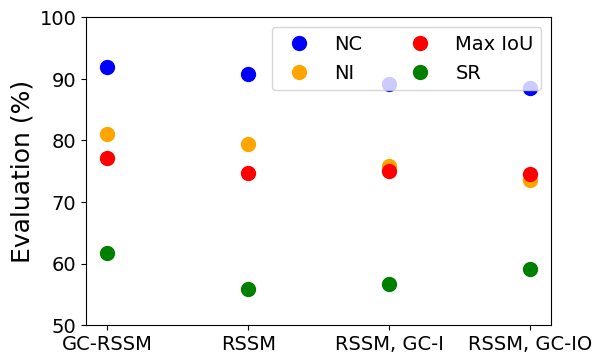

In [6]:
recon_df = df[(df['config'].str.contains('recon'))]
recon_df = recon_df[~recon_df['config'].str.contains('RGB2M')]

display(recon_df)

agent_config2label = {
    ('rssm', 'recon-RGB2RGB'): 'RSSM',
    ('rssm', 'recon-GC-Input-Only-RGB2RGB'): 'RSSM, GC-I',
    ('rssm', 'recon-GC-IO-RGB2RGB'): 'RSSM, GC-IO',
    ('gc_rssm', 'recon-RGB2RGB'): 'GC-RSSM'
}


custom_order = list(agent_config2label.keys())

print(custom_order)

recon_df['agent_config'] = list(zip(recon_df['agent'], recon_df['config']))

# Map the tuple to the label
recon_df['label'] = recon_df['agent_config'].map(agent_config2label)

# Map each ('agent', 'config') pair to its position in the custom order
recon_df['sort_key'] = recon_df[['agent', 'config']].apply(tuple, axis=1).map({k: i for i, k in enumerate(custom_order)})

# Sort by the custom key
recon_df = recon_df.sort_values('sort_key').drop(columns=['sort_key'])

recon_df = recon_df.groupby('label').agg({
    'nc': 'mean',
    'IoU': 'mean',
    'ni': 'mean',
    'episodes': 'sum',
    'success_eps': 'sum'
}).reset_index()



## get the f1 score for each config using NC and IoU
recon_df['f1'] = 2*recon_df['nc']*recon_df['IoU']/(recon_df['nc'] + recon_df['IoU'])
recon_df['f1'] = recon_df['f1']*100
recon_df['sr'] = recon_df['success_eps']/recon_df['episodes'] * 100
# s
display(recon_df)

y_min = 50
y_max = 100


## show goal augmentation
goal_df = recon_df
## get rid of " Augmentation" in the config
# goal_df['config'] = goal_df['config'].str.replace(' Augmentation', '')
# plt.plot(goal_df['label'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
# plt.plot(goal_df['label'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')

plt.figure(figsize=(6, 4))  # Optional: make the figure larger

plt.ylabel('Evaluation (%)', fontsize=18)
plt.plot(goal_df['label'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC', markersize=10)
plt.plot(goal_df['label'], goal_df['ni']*100, color='orange', marker='o', linestyle='', label='NI', markersize=10)
plt.plot(goal_df['label'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU', markersize=10)
plt.plot(goal_df['label'], goal_df['sr'], color='green', marker='o', linestyle='', label='SR', markersize=10)

plt.ylim(y_min, y_max)
plt.legend(fontsize=14,ncol=2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
# plt.title('F1 Score for Reward Ablation', fontsize=20)
# plt.title('F1 Score for Goal Augmentation', fontsize=20)

plt.savefig(os.path.join(analysis_pth, 'goal-ablation.png'), bbox_inches='tight')
plt.show()


,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
58,flattening,gc_rssm,cf-reward,longsleeve,0.001793,0.378817,0.009655,0.051654,0.364330,0.152572,0.044070,0.029466,20.000000,0.000000,30,0,../test_results/evals/gc_rssm/cf-reward/longsl...,50000
59,flattening,gc_rssm,cf-reward,pants,0.035273,0.494704,0.094111,0.070345,0.448039,0.074822,0.048995,0.013326,20.000000,0.000000,30,0,../test_results/evals/gc_rssm/cf-reward/pants,50000
60,flattening,gc_rssm,cf-reward,skirt,0.000000,0.365988,0.000000,0.047222,0.348704,0.104232,0.045599,0.015624,20.000000,0.000000,30,0,../test_results/evals/gc_rssm/cf-reward/skirt,50000
61,flattening,gc_rssm,cf-reward,dress,0.012584,0.442072,0.034485,0.061207,0.420062,0.093873,0.056268,0.015074,20.000000,0.000000,30,0,../test_results/evals/gc_rssm/cf-reward/dress,50000
64,flattening,gc_rssm,sfp-reward,longsleeve,0.699161,0.858943,0.243782,0.106967,0.685190,0.072505,0.121361,0.030177,17.066667,4.966107,30,9,../test_results/evals/gc_rssm/sfp-reward/longs...,50000
65,flattening,gc_rssm,sfp-reward,pants,0.881070,0.949675,0.089327,0.043621,0.753299,0.039699,0.122286,0.017921,13.700000,6.197580,30,20,../test_results/evals/gc_rssm/sfp-reward/pants,50000
66,flattening,gc_rssm,sfp-reward,skirt,0.783326,0.905326,0.148685,0.076224,0.837766,0.038403,0.057823,0.013764,10.433333,6.081027,30,25,../test_results/evals/gc_rssm/sfp-reward/skirt,50000
67,flattening,gc_rssm,sfp-reward,dress,0.752060,0.899149,0.191905,0.075212,0.810907,0.040447,0.064615,0.014076,10.600000,6.775446,30,23,../test_results/evals/gc_rssm/sfp-reward/dress,50000
76,flattening,gc_rssm,RGB2M-on-mix-800k-all-garment-bonus-penalty-v3...,longsleeve,0.711329,0.861542,0.241383,0.127617,0.667308,0.078104,0.121236,0.028029,17.866667,4.917542,30,8,../test_results/evals/gc_rssm/RGB2M-on-mix-800...,50000
77,flattening,gc_rssm,RGB2M-on-mix-800k-all-garment-bonus-penalty-v3...,pants,0.847393,0.931829,0.137847,0.068163,0.725728,0.044020,0.136127,0.020696,13.500000,6.391400,30,17,../test_results/evals/gc_rssm/RGB2M-on-mix-800...,50000


[('gc_rssm', 'pc-reward'), ('gc_rssm', 'cf-reward'), ('gc_rssm', 'sfp-reward'), ('gc_rssm', 'l2f-reward'), ('gc_rssm', 'ca-reward')]


/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = va

,label,nc,IoU,ni,episodes,success_eps,f1,sr
0,CA(ours),0.922991,0.796284,0.824905,120,91,85.496851,75.833333
1,CF,0.420395,0.395284,0.012412,120,0,40.745313,0.000000
2,L2U,0.771677,0.665565,0.501958,120,28,71.470380,23.333333
3,PC,0.843329,0.701693,0.640837,120,35,76.601865,29.166667
4,SF,0.903273,0.771790,0.778904,120,77,83.237154,64.166667


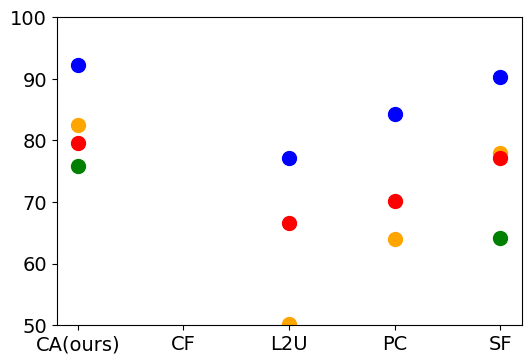

In [7]:
# TODO: plot comparesion between ca, sfp, pc, l2f

recon_df = df[(df['config'].str.contains('reward'))]

display(recon_df)

agent_config2label = {
    ('gc_rssm', 'pc-reward'): 'PC',
    ('gc_rssm', 'cf-reward'): 'CF',
    ('gc_rssm', 'sfp-reward'): 'SF',
    ('gc_rssm', 'l2f-reward'): 'L2U',
    ('gc_rssm', 'ca-reward'): 'CA(ours)'
}


custom_order = list(agent_config2label.keys())

print(custom_order)

recon_df['agent_config'] = list(zip(recon_df['agent'], recon_df['config']))

# Map the tuple to the label
recon_df['label'] = recon_df['agent_config'].map(agent_config2label)

# Map each ('agent', 'config') pair to its position in the custom order
recon_df['sort_key'] = recon_df[['agent', 'config']].apply(tuple, axis=1).map({k: i for i, k in enumerate(custom_order)})

# Sort by the custom key
recon_df = recon_df.sort_values('sort_key').drop(columns=['sort_key'])

recon_df = recon_df.groupby('label').agg({
    'nc': 'mean',
    'IoU': 'mean',
    'ni': 'mean',
    'episodes': 'sum',
    'success_eps': 'sum'
}).reset_index()



## get the f1 score for each config using NC and IoU
recon_df['f1'] = 2*recon_df['nc']*recon_df['IoU']/(recon_df['nc'] + recon_df['IoU'])
recon_df['f1'] = recon_df['f1']*100
recon_df['sr'] = recon_df['success_eps']/recon_df['episodes'] * 100
# s
display(recon_df)

y_min = 50
y_max = 100


## show goal augmentation
goal_df = recon_df
## get rid of " Augmentation" in the config
# goal_df['config'] = goal_df['config'].str.replace(' Augmentation', '')
# plt.plot(goal_df['label'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
# plt.plot(goal_df['label'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')

plt.figure(figsize=(6, 4))  # Optional: make the figure larger

# plt.ylabel('Evaluation (%)', fontsize=18)
plt.plot(goal_df['label'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC', markersize=10)
plt.plot(goal_df['label'], goal_df['ni']*100, color='orange', marker='o', linestyle='', label='NI', markersize=10)
plt.plot(goal_df['label'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU', markersize=10)
plt.plot(goal_df['label'], goal_df['sr'], color='green', marker='o', linestyle='', label='SR', markersize=10)

plt.ylim(y_min, y_max)
# plt.legend(fontsize=14,ncol=2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
# plt.title('F1 Score for Reward Ablation', fontsize=20)
# plt.title('F1 Score for Goal Augmentation', fontsize=20)

plt.savefig(os.path.join(analysis_pth, 'reward-ablation.png'), bbox_inches='tight')
plt.show()
